# Seasonal Agriculture Performance Analysis

**Objective:** Analyse the agricultural dataset to understand how agricultural performance (yield, profitability, resource efficiency and risk) differs across the three Indian cropping seasons — **Kharif, Rabi and Zaid** — and which patterns, relationships and variations explain those differences.

**Notebook outline**
1. Setup & data loading
2. Data understanding
3. Data cleaning (missing values, duplicates, consistency checks, outliers, categorical checks)
4. Feature engineering
5. Exploratory data analysis
6. Seasonal analysis (core of the project)
7. Statistical significance testing
8. Crop × Season, Irrigation × Season, State × Season
9. Drivers of performance (correlation + Random Forest)
10. Key findings & recommendations

## 1. Setup & data loading

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from itertools import combinations
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_columns", 50, "display.width", 200)

SEASON_ORDER = ["Kharif", "Rabi", "Zaid"]
SEASON_COLORS = {"Kharif": "#2E7D32", "Rabi": "#F9A825", "Zaid": "#D84315"}
os.makedirs("figures", exist_ok=True)

def savefig(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

df = pd.read_csv("seasonal_agriculture_performance_dataset.csv")
print("Shape:", df.shape)
df.head()

Shape: (4000, 28)


,Farm_ID,State,District,Crop,Season,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,Soil_pH,Soil_Moisture_pct,Nitrogen_kg_ha,Phosphorus_kg_ha,Potassium_kg_ha,Irrigation_Method,Fertilizer_kg_ha,Pesticide_Litre_ha,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
0,SF10001,Andhra Pradesh,Rajkot,Wheat,Kharif,0.53,486.4,24.3,69.1,5.8,7.14,32.8,75.8,61.3,91.0,Drip,242.7,4.33,0.76,2.46,1.30,23700,42662,30810,-11852,237,5.485,55.3
1,SF10002,Maharashtra,Nalgonda,Maize,Kharif,6.53,855.4,25.7,78.4,5.1,5.20,32.0,82.1,35.4,121.8,Flood,271.4,6.86,0.94,0.30,1.96,20613,492351,40401,-451950,4953,0.396,49.9
2,SF10003,Telangana,Warangal,Pulses,Rabi,4.86,455.6,23.9,56.4,10.3,5.82,8.1,118.5,51.5,117.9,Drip,162.6,6.08,0.98,0.52,2.53,75283,315210,190466,-124744,1275,1.984,33.7
3,SF10004,Telangana,Indore,Rice,Kharif,4.50,753.2,29.7,65.2,6.3,5.98,23.7,138.6,55.6,115.5,Rainfed,182.2,6.39,0.74,1.84,8.28,24244,296444,200740,-95704,3834,2.160,50.6
4,SF10005,Karnataka,Ludhiana,Maize,Zaid,4.21,101.6,34.1,55.2,6.5,6.90,29.3,124.1,69.0,121.4,Flood,244.9,7.61,0.90,2.21,9.30,20818,337959,193607,-144352,3287,2.829,32.3


## 2. Data understanding

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 28 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Farm_ID                        4000 non-null   str    
 1   State                          4000 non-null   str    
 2   District                       4000 non-null   str    
 3   Crop                           4000 non-null   str    
 4   Season                         4000 non-null   str    
 5   Farm_Area_Hectares             4000 non-null   float64
 6   Rainfall_mm                    3952 non-null   float64
 7   Avg_Temperature_C              4000 non-null   float64
 8   Humidity_pct                   4000 non-null   float64
 9   Sunlight_Hours_Day             4000 non-null   float64
 10  Soil_pH                        4000 non-null   float64
 11  Soil_Moisture_pct              3960 non-null   float64
 12  Nitrogen_kg_ha                 4000 non-null   float64
 13 

In [3]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Farm_Area_Hectares,4000.0,7.89,4.22,0.50,4.26,7.90,11.65,15.00
Rainfall_mm,3952.0,601.15,288.93,80.00,370.20,582.00,834.95,1395.20
Avg_Temperature_C,4000.0,26.82,3.82,16.20,23.90,26.90,29.60,39.70
Humidity_pct,4000.0,63.21,11.96,25.00,54.78,63.00,71.90,95.00
Sunlight_Hours_Day,4000.0,7.32,1.12,3.50,6.60,7.30,8.10,11.00
Soil_pH,4000.0,6.70,0.64,5.20,6.26,6.69,7.14,8.40
Soil_Moisture_pct,3960.0,26.51,6.71,8.00,21.70,26.40,31.30,47.00
Nitrogen_kg_ha,4000.0,120.25,31.22,40.00,98.50,120.10,141.22,220.00
Phosphorus_kg_ha,4000.0,57.78,17.02,15.00,46.20,57.50,69.40,120.00
Potassium_kg_ha,4000.0,104.76,27.74,30.00,86.20,105.10,123.60,200.00


In [4]:
cat_cols = ["State", "District", "Crop", "Season", "Irrigation_Method"]
for c in cat_cols:
    print(f"{c}  ({df[c].nunique()} unique)")
    print(df[c].value_counts().to_string(), "\n")

State  (8 unique)
State
Andhra Pradesh    529
Telangana         516
Maharashtra       512
Madhya Pradesh    497
Karnataka         489
Gujarat           488
Tamil Nadu        485
Punjab            484 

District  (10 unique)
District
Ludhiana    427
Warangal    422
Nalgonda    415
Erode       403
Rajkot      401
Krishna     393
Indore      392
Guntur      390
Raichur     386
Nashik      371 

Crop  (8 unique)
Crop
Rice         690
Wheat        614
Maize        551
Cotton       508
Pulses       496
Groundnut    424
Chilli       412
Sugarcane    305 

Season  (3 unique)
Season
Kharif    1779
Rabi      1627
Zaid       594 

Irrigation_Method  (4 unique)
Irrigation_Method
Flood        1310
Rainfed      1041
Drip          915
Sprinkler     734 



**Observations**
- 4,000 farms, 28 columns: identifiers, location, crop & season, weather, soil, inputs, outputs, economics and risk.
- Three columns have missing values (`Rainfall_mm`, `Soil_Moisture_pct`, `Yield_Tonnes_Ha`).
- `Yield_Tonnes_Ha` has a maximum of ~101 against a median of ~1.7 — this must be investigated before it is treated as an error.

## 3. Data cleaning

### 3.1 Missing values

In [5]:
missing = pd.DataFrame({"missing": df.isna().sum(), "pct": (df.isna().mean() * 100).round(2)})
missing[missing.missing > 0]

,missing,pct
Rainfall_mm,48,1.2
Soil_Moisture_pct,40,1.0
Yield_Tonnes_Ha,32,0.8


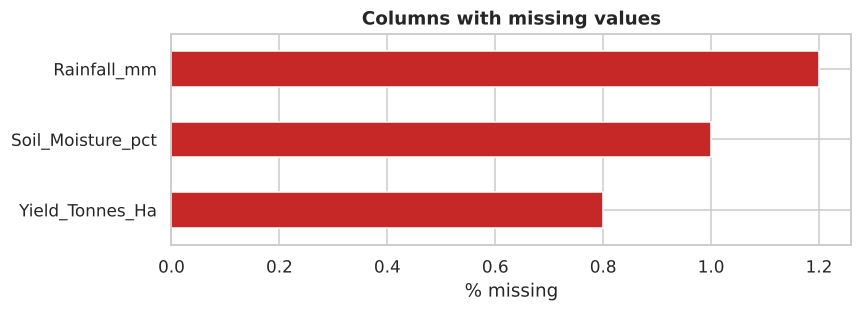

In [6]:
plt.figure(figsize=(8, 3))
m = missing[missing.missing > 0]["pct"].sort_values()
m.plot.barh(color="#C62828")
plt.xlabel("% missing"); plt.title("Columns with missing values")
savefig("01_missing_values")

### 3.2 Duplicates & identifiers

In [7]:
print("Duplicate rows       :", df.duplicated().sum())
print("Duplicate Farm_IDs   :", df["Farm_ID"].duplicated().sum())
print("Whitespace in text   :", sum((df[c].astype(str) != df[c].astype(str).str.strip()).sum() for c in cat_cols))

Duplicate rows       : 0
Duplicate Farm_IDs   : 0
Whitespace in text   : 0


### 3.3 Internal-consistency checks
Several columns are derived from others. Verifying these relationships tells us (a) whether the data is trustworthy and (b) how to **recover** missing values exactly instead of guessing them.

In [8]:
prod_chk   = (df["Yield_Tonnes_Ha"] * df["Farm_Area_Hectares"] - df["Production_Tonnes"]).abs()
rev_chk    = (df["Production_Tonnes"] * df["Market_Price_INR_Tonne"] - df["Revenue_INR"]).abs()
profit_chk = (df["Revenue_INR"] - df["Total_Cost_INR"] - df["Profit_INR"]).abs()
water_chk  = (df["Production_Tonnes"] / df["Water_Used_m3"] * 1000 - df["Water_Efficiency_t_per_1000m3"]).abs()

print("Yield x Area  vs Production   -> max abs diff:", round(prod_chk.max(), 3), "tonnes")
print("Production x Price vs Revenue -> max abs diff:", round(rev_chk.max(), 1), "INR (rounding)")
print("Revenue - Cost vs Profit      -> max abs diff:", profit_chk.max(), "INR")
print("Production/Water vs Efficiency-> max abs diff:", round(water_chk.max(), 4))

Yield x Area  vs Production   -> max abs diff: 0.005 tonnes
Production x Price vs Revenue -> max abs diff: 0.5 INR (rounding)
Revenue - Cost vs Profit      -> max abs diff: 0 INR
Production/Water vs Efficiency-> max abs diff: 0.0005


All derived columns reconcile (differences are only rounding). So, for the 32 rows missing `Yield_Tonnes_Ha`, the exact value can be recovered as **Production ÷ Area** — no estimation required.

### 3.4 Treating the missing values

In [9]:
clean = df.copy()

# (a) Yield: recover exactly from Production / Area
n_before = clean["Yield_Tonnes_Ha"].isna().sum()
mask = clean["Yield_Tonnes_Ha"].isna()
clean.loc[mask, "Yield_Tonnes_Ha"] = (clean.loc[mask, "Production_Tonnes"] / clean.loc[mask, "Farm_Area_Hectares"]).round(2)
print(f"Yield recovered from Production/Area: {n_before} -> {clean['Yield_Tonnes_Ha'].isna().sum()} missing")

# (b) Rainfall is strongly season-driven, so impute with the SEASON median
print("\nMedian rainfall by season:\n", clean.groupby("Season")["Rainfall_mm"].median().round(1).to_string())
clean["Rainfall_mm"] = clean["Rainfall_mm"].fillna(clean.groupby("Season")["Rainfall_mm"].transform("median"))

# (c) Soil moisture: check what it depends on before choosing the imputation group
print("\nMedian soil moisture by Irrigation_Method x Season:")
print(clean.pivot_table(index="Irrigation_Method", columns="Season", values="Soil_Moisture_pct", aggfunc="median").round(1))

Yield recovered from Production/Area: 32 -> 0 missing

Median rainfall by season:
 Season
Kharif    854.8
Rabi      430.3
Zaid      283.3

Median soil moisture by Irrigation_Method x Season:
Season             Kharif  Rabi  Zaid
Irrigation_Method                    
Drip                 31.2  24.5  18.4
Flood                31.2  24.0  19.4
Rainfed              30.9  24.1  19.8
Sprinkler            31.5  22.9  18.4


In [10]:
clean["Soil_Moisture_pct"] = clean["Soil_Moisture_pct"].fillna(
    clean.groupby(["Irrigation_Method", "Season"])["Soil_Moisture_pct"].transform("median"))
print("Remaining missing values:", clean.isna().sum().sum())

Remaining missing values: 0


### 3.5 Outlier investigation
`Yield_Tonnes_Ha` looks extreme at first glance. A global IQR rule would flag hundreds of rows — but yield is **crop-specific** (sugarcane yields tens of tonnes/ha, pulses ~1). Outliers must therefore be judged *within each crop*.

Global IQR rule flags: 304 rows (misleading)

           count   min    50%     max
Crop                                 
Chilli     412.0  0.30   1.56    3.90
Cotton     508.0  0.30   1.24    2.90
Groundnut  424.0  0.30   1.40    3.02
Maize      551.0  0.30   2.85    6.08
Pulses     496.0  0.30   0.94    2.09
Rice       690.0  0.30   2.46    5.70
Sugarcane  305.0  1.39  48.03  101.44
Wheat      614.0  0.30   2.22    4.56


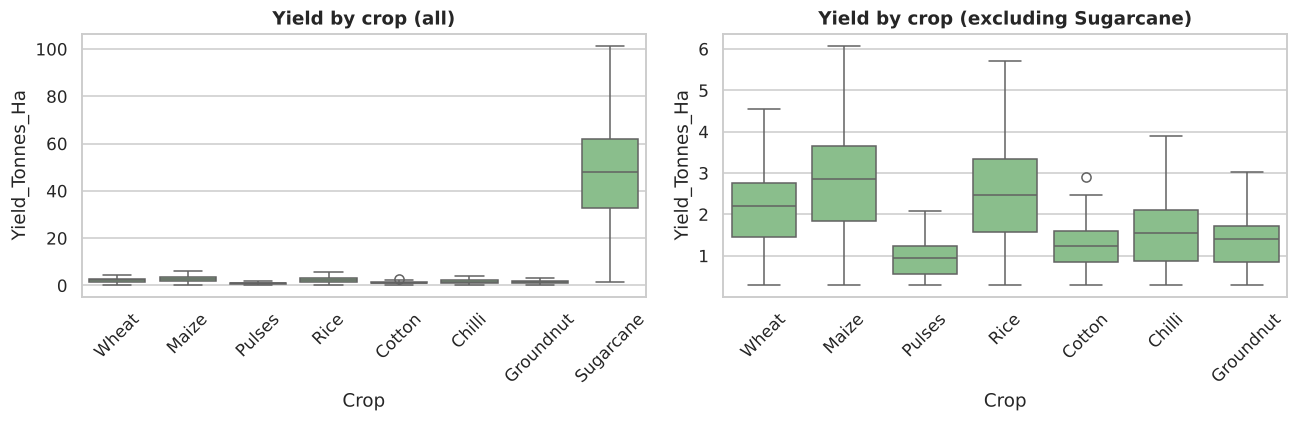

In [11]:
print("Global IQR rule flags:", ((clean["Yield_Tonnes_Ha"] > clean["Yield_Tonnes_Ha"].quantile(.75) + 1.5*stats.iqr(clean["Yield_Tonnes_Ha"]))).sum(), "rows (misleading)\n")
print(clean.groupby("Crop")["Yield_Tonnes_Ha"].describe()[["count","min","50%","max"]].round(2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=clean, x="Crop", y="Yield_Tonnes_Ha", ax=ax[0], color="#81C784"); ax[0].tick_params(axis="x", rotation=45); ax[0].set_title("Yield by crop (all)")
sns.boxplot(data=clean[clean.Crop != "Sugarcane"], x="Crop", y="Yield_Tonnes_Ha", ax=ax[1], color="#81C784"); ax[1].tick_params(axis="x", rotation=45); ax[1].set_title("Yield by crop (excluding Sugarcane)")
savefig("02_yield_outlier_check")

In [12]:
# Within-crop IQR outlier flags (flag, don't delete — values are physically plausible)
def iqr_flag(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return (s < q1 - 1.5*i) | (s > q3 + 1.5*i)

clean["Yield_Outlier"]  = clean.groupby("Crop")["Yield_Tonnes_Ha"].transform(iqr_flag)
clean["Profit_Outlier"] = clean.groupby("Crop")["Profit_INR"].transform(iqr_flag)
print("Within-crop yield outliers :", clean["Yield_Outlier"].sum())
print("Within-crop profit outliers:", clean["Profit_Outlier"].sum())

# Yield floor check
print("\nRows at the minimum yield value (0.30):", (clean["Yield_Tonnes_Ha"] == 0.30).sum(), "-> likely a recorded floor (crop failure / lower bound)")

# Range checks on agronomic variables
checks = {"Soil_pH (4-9)": clean.Soil_pH.between(4, 9), "Humidity (0-100)": clean.Humidity_pct.between(0, 100),
          "Soil moisture (0-100)": clean.Soil_Moisture_pct.between(0, 100), "Seed quality (0-1)": clean.Seed_Quality_Score.between(0, 1),
          "Disease risk (0-100)": clean.Disease_Pest_Risk_pct.between(0, 100), "Area > 0": clean.Farm_Area_Hectares > 0}
print("\nRange validation (rows violating):")
for k, v in checks.items(): print(f"  {k:<24}: {(~v).sum()}")

Within-crop yield outliers : 1
Within-crop profit outliers: 201

Rows at the minimum yield value (0.30): 223 -> likely a recorded floor (crop failure / lower bound)

Range validation (rows violating):
  Soil_pH (4-9)           : 0
  Humidity (0-100)        : 0
  Soil moisture (0-100)   : 0
  Seed quality (0-1)      : 0
  Disease risk (0-100)    : 0
  Area > 0                : 0


**Outlier decision:** The very high yields belong to **sugarcane** and are agronomically realistic (30–100 t/ha). All values stay within valid ranges, so **no rows are deleted**. Outliers are *flagged* and — importantly — yield is compared across seasons using a **crop-normalised index** (section 4) so that sugarcane does not dominate the averages.

### 3.6 Location-field sanity check

In [13]:
pd.crosstab(clean["State"], clean["District"])

District,Erode,Guntur,Indore,Krishna,Ludhiana,Nalgonda,Nashik,Raichur,Rajkot,Warangal
State,,,,,,,,,,
Andhra Pradesh,45,49,47,54,56,57,44,63,65,49
Gujarat,61,58,34,35,54,54,39,52,48,53
Karnataka,39,44,42,54,56,52,52,44,58,48
Madhya Pradesh,39,51,48,54,57,50,43,47,46,62
Maharashtra,47,53,51,59,46,57,54,46,52,47
Punjab,53,46,45,56,48,49,50,43,37,57
Tamil Nadu,51,52,54,39,61,34,41,56,48,49
Telangana,68,37,71,42,49,62,48,35,47,57


Every district appears under every state (e.g. *Rajkot* under Andhra Pradesh), so `District` is **not a reliable geographic hierarchy** in this dataset. We therefore use `State` for regional analysis and treat `District` as a non-informative label. This is stated as a limitation in the final section.

## 4. Feature engineering

In [14]:
c = clean
c["Cost_per_ha"]        = c["Total_Cost_INR"] / c["Farm_Area_Hectares"]
c["Revenue_per_ha"]     = c["Revenue_INR"]    / c["Farm_Area_Hectares"]
c["Profit_per_ha"]      = c["Profit_INR"]     / c["Farm_Area_Hectares"]
c["Profit_Margin_pct"]  = c["Profit_INR"] / c["Revenue_INR"] * 100
c["Is_Profitable"]      = (c["Profit_INR"] > 0).astype(int)
c["Water_per_ha_m3"]    = c["Water_Used_m3"] / c["Farm_Area_Hectares"]
c["NPK_Total_kg_ha"]    = c["Nitrogen_kg_ha"] + c["Phosphorus_kg_ha"] + c["Potassium_kg_ha"]

# Crop-normalised yield: 1.0 = typical (median) yield for that crop -> comparable across crops
c["Yield_Index"] = c["Yield_Tonnes_Ha"] / c.groupby("Crop")["Yield_Tonnes_Ha"].transform("median")

c["Rainfall_Category"] = pd.cut(c["Rainfall_mm"], [0, 300, 600, 900, np.inf], labels=["Low (<300)", "Moderate (300-600)", "High (600-900)", "Very high (>900)"])
c["Season"] = pd.Categorical(c["Season"], SEASON_ORDER, ordered=True)

print("New features:", ["Cost_per_ha","Revenue_per_ha","Profit_per_ha","Profit_Margin_pct","Is_Profitable","Water_per_ha_m3","NPK_Total_kg_ha","Yield_Index","Rainfall_Category"])
c[["Crop","Season","Yield_Tonnes_Ha","Yield_Index","Profit_per_ha","Profit_Margin_pct","Is_Profitable"]].head()

New features: ['Cost_per_ha', 'Revenue_per_ha', 'Profit_per_ha', 'Profit_Margin_pct', 'Is_Profitable', 'Water_per_ha_m3', 'NPK_Total_kg_ha', 'Yield_Index', 'Rainfall_Category']


,Crop,Season,Yield_Tonnes_Ha,Yield_Index,Profit_per_ha,Profit_Margin_pct,Is_Profitable
0,Wheat,Kharif,2.46,1.110609,-22362.264151,-38.468030,0
1,Maize,Kharif,0.30,0.105263,-69211.332312,-1118.660429,0
2,Pulses,Rabi,0.52,0.553191,-25667.489712,-65.494104,0
3,Rice,Kharif,1.84,0.747967,-21267.555556,-47.675600,0
4,Maize,Zaid,2.21,0.775439,-34287.885986,-74.559288,0


In [15]:
clean.to_csv("cleaned_agriculture_data.csv", index=False)
print("Cleaned dataset saved:", clean.shape, "| missing values:", clean.isna().sum().sum())

Cleaned dataset saved: (4000, 39) | missing values: 0


## 5. Exploratory data analysis

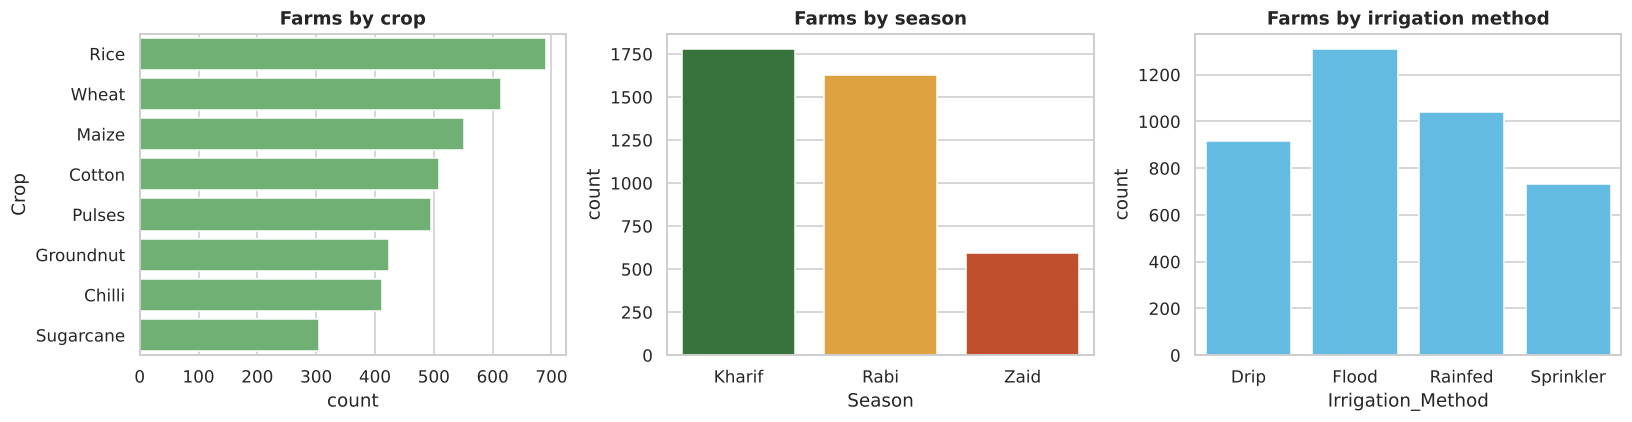

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
order = clean["Crop"].value_counts().index
sns.countplot(data=clean, y="Crop", order=order, color="#66BB6A", ax=ax[0]); ax[0].set_title("Farms by crop")
sns.countplot(data=clean, x="Season", order=SEASON_ORDER, palette=SEASON_COLORS, ax=ax[1]); ax[1].set_title("Farms by season")
sns.countplot(data=clean, x="Irrigation_Method", color="#4FC3F7", ax=ax[2]); ax[2].set_title("Farms by irrigation method")
savefig("03_category_distribution")

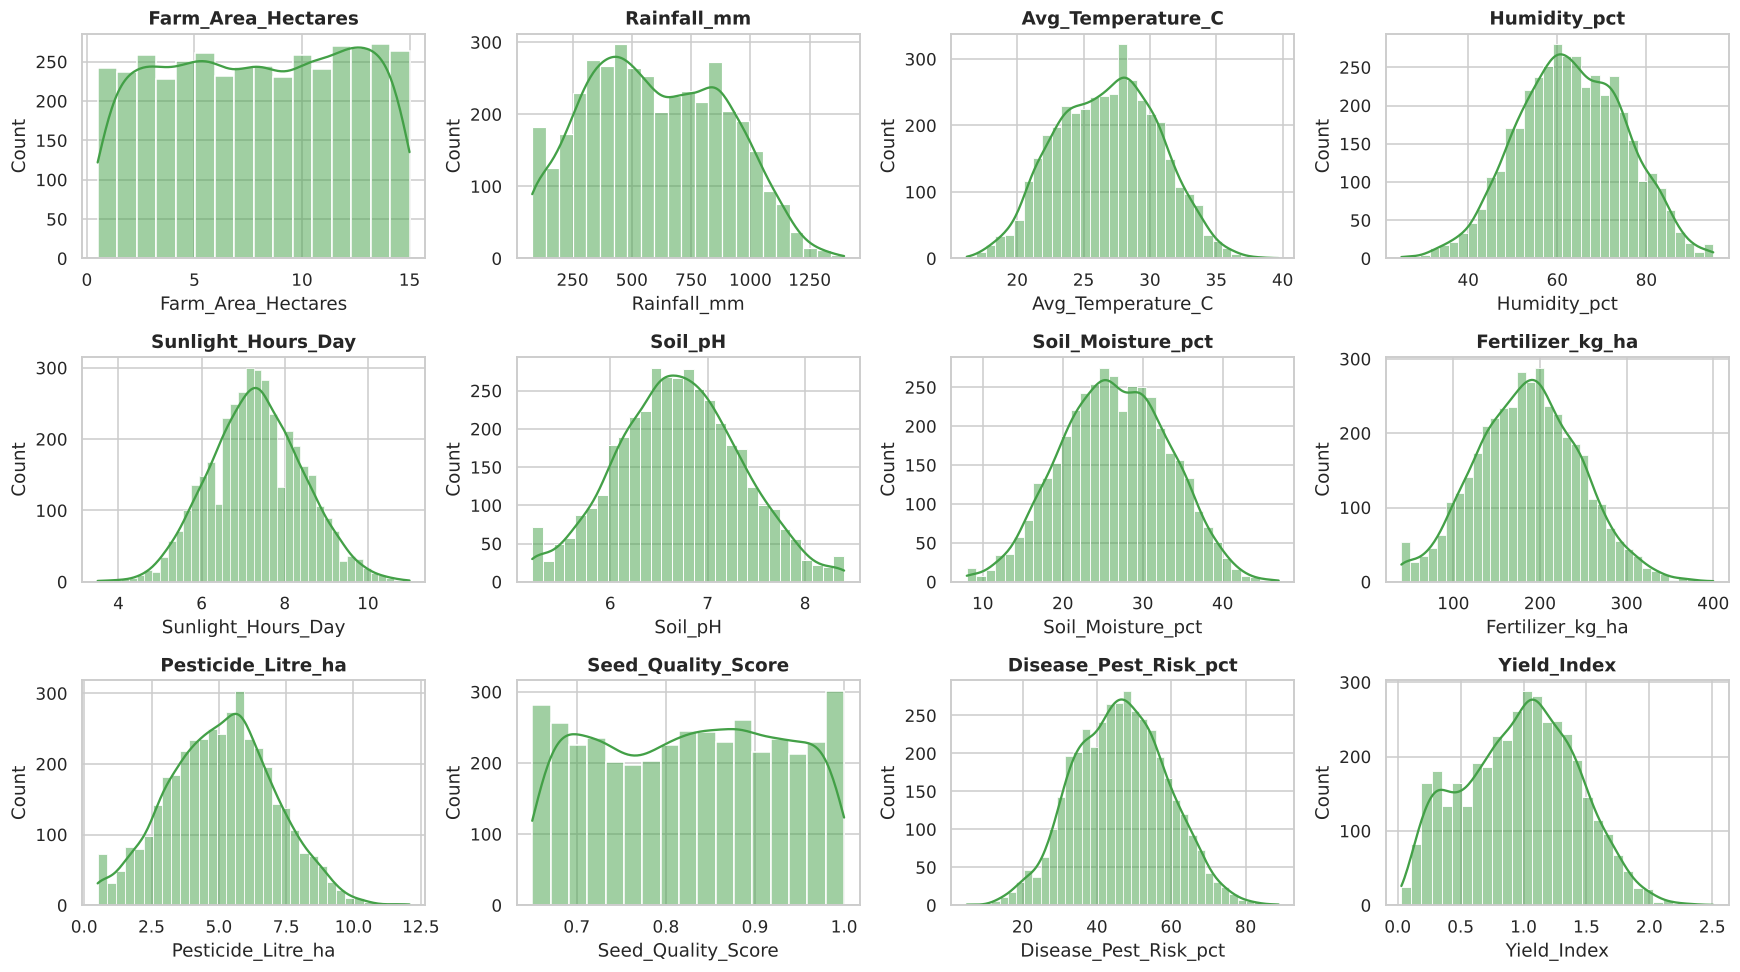

In [17]:
num = ["Farm_Area_Hectares","Rainfall_mm","Avg_Temperature_C","Humidity_pct","Sunlight_Hours_Day","Soil_pH","Soil_Moisture_pct",
       "Fertilizer_kg_ha","Pesticide_Litre_ha","Seed_Quality_Score","Disease_Pest_Risk_pct","Yield_Index"]
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for a, col in zip(axes.ravel(), num):
    sns.histplot(clean[col], kde=True, ax=a, color="#43A047"); a.set_title(col)
savefig("04_numeric_distributions")

In [18]:
print("Overall profitability:", f"{clean.Is_Profitable.mean()*100:.1f}% of farms made a profit")
print("Median profit per farm: INR", f"{clean.Profit_INR.median():,.0f}")
print("Mean  profit per farm : INR", f"{clean.Profit_INR.mean():,.0f}")

Overall profitability: 50.8% of farms made a profit
Median profit per farm: INR 3,673
Mean  profit per farm : INR 111,556


## 6. Seasonal analysis

### 6.1 Season-wise performance scorecard

In [19]:
kpi = clean.groupby("Season", observed=True).agg(
    Farms=("Farm_ID", "count"),
    Avg_Yield_Index=("Yield_Index", "mean"),
    Median_Profit_per_ha=("Profit_per_ha", "median"),
    Median_Profit_Margin_pct=("Profit_Margin_pct", "median"),
    Pct_Profitable=("Is_Profitable", lambda s: s.mean()*100),
    Avg_Cost_per_ha=("Cost_per_ha", "mean"),
    Avg_Revenue_per_ha=("Revenue_per_ha", "mean"),
    Avg_Water_Efficiency=("Water_Efficiency_t_per_1000m3", "mean"),
    Avg_Disease_Risk_pct=("Disease_Pest_Risk_pct", "mean"),
).round(2)
kpi.T

Season,Kharif,Rabi,Zaid
Farms,1779.00,1627.00,594.00
Avg_Yield_Index,1.08,0.93,0.77
Median_Profit_per_ha,8340.45,-894.33,-13760.26
Median_Profit_Margin_pct,11.09,-1.34,-24.59
Pct_Profitable,57.79,48.86,35.52
Avg_Cost_per_ha,66900.98,66295.24,66937.94
Avg_Revenue_per_ha,88782.79,76656.92,64301.42
Avg_Water_Efficiency,5.89,5.19,4.41
Avg_Disease_Risk_pct,54.47,40.48,38.22


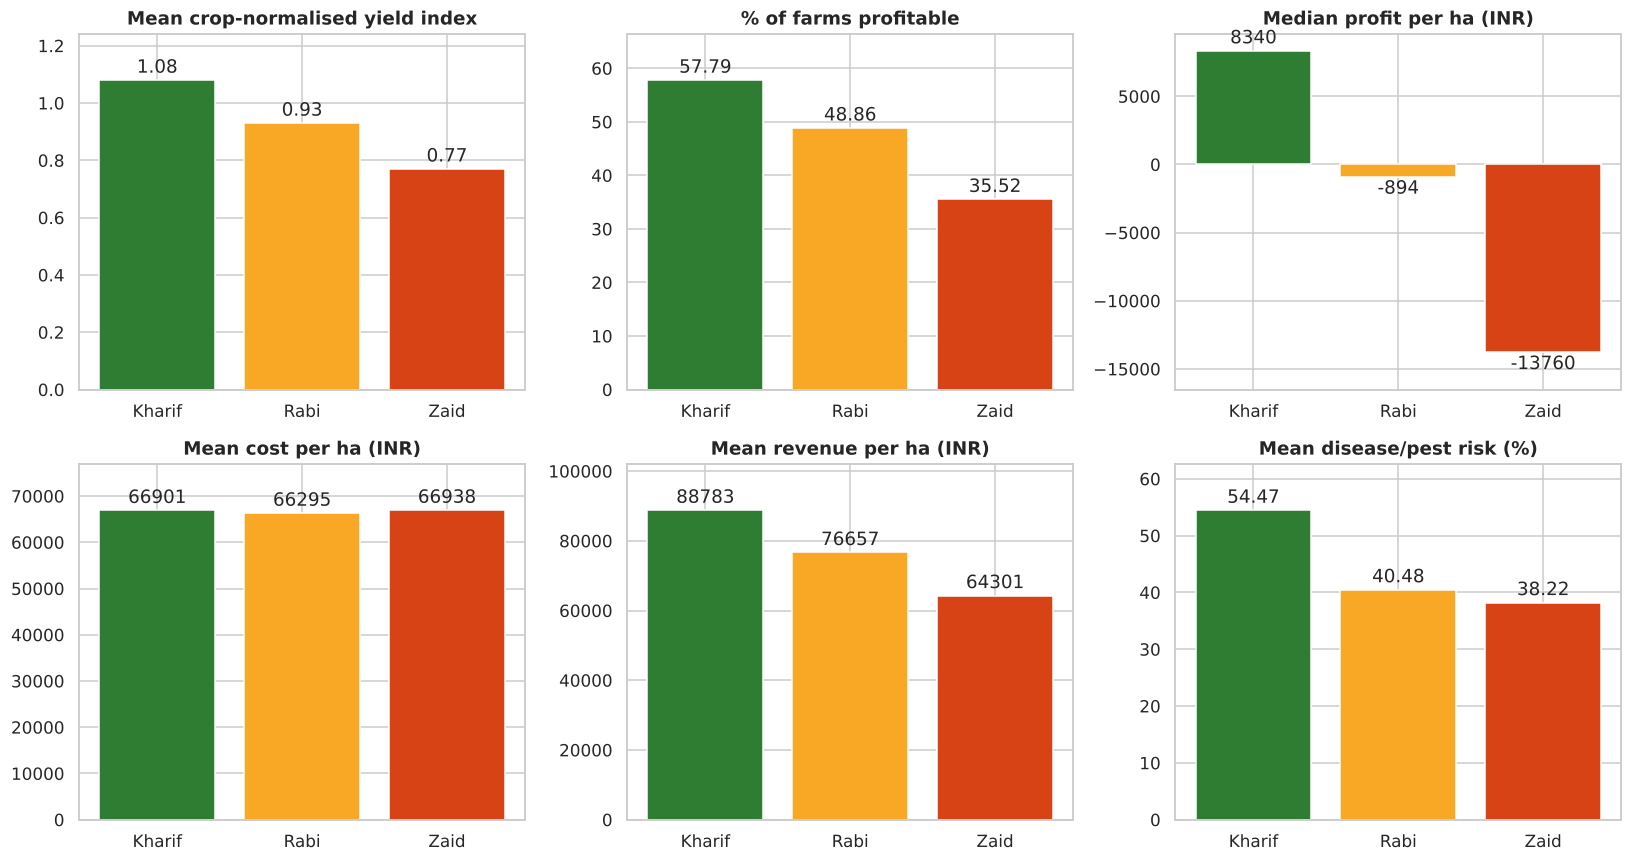

In [20]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
specs = [("Avg_Yield_Index","Mean crop-normalised yield index"),("Pct_Profitable","% of farms profitable"),("Median_Profit_per_ha","Median profit per ha (INR)"),
         ("Avg_Cost_per_ha","Mean cost per ha (INR)"),("Avg_Revenue_per_ha","Mean revenue per ha (INR)"),("Avg_Disease_Risk_pct","Mean disease/pest risk (%)")]
for a, (col, title) in zip(ax.ravel(), specs):
    bars = a.bar(kpi.index.astype(str), kpi[col], color=[SEASON_COLORS[s] for s in kpi.index])
    a.set_title(title); a.bar_label(bars, fmt="%.2f" if kpi[col].max() < 100 else "%.0f", padding=2)
    a.set_ylim(min(0, kpi[col].min()*1.2), kpi[col].max()*1.15)
savefig("05_season_scorecard")

### 6.2 Environmental conditions by season

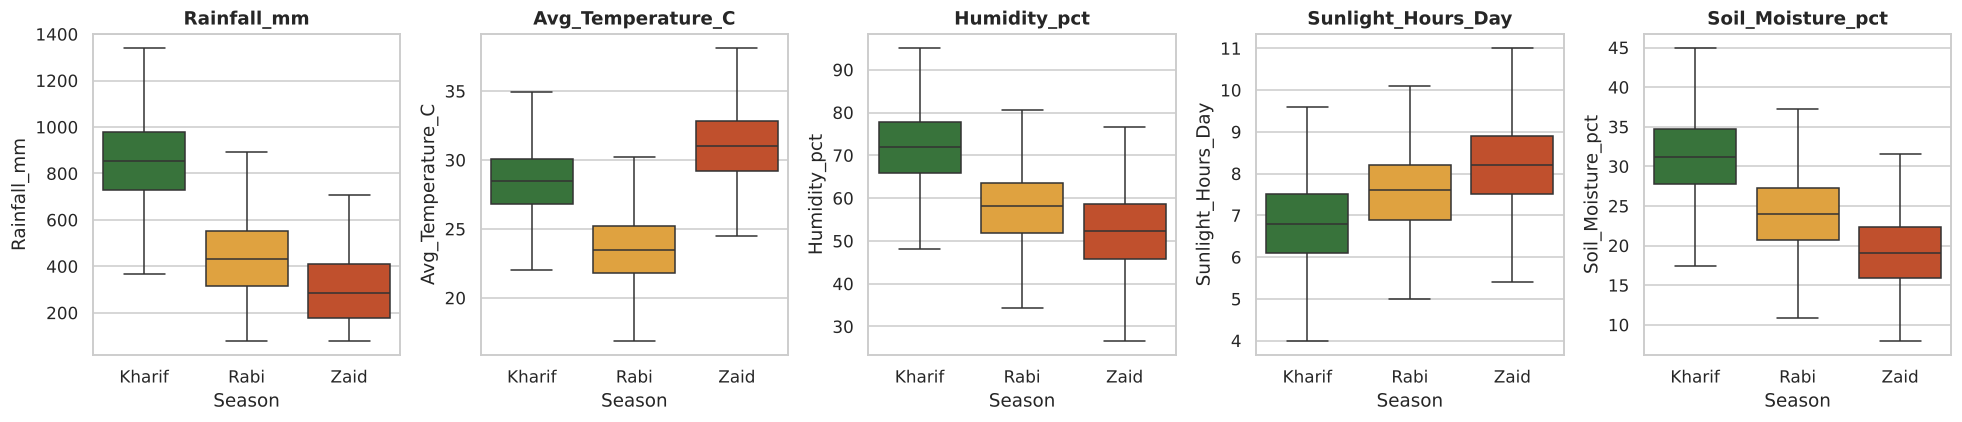

,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,Soil_Moisture_pct
Season,,,,,
Kharif,852.1,28.5,71.8,6.8,31.2
Rabi,435.9,23.5,57.9,7.6,24.0
Zaid,299.1,31.0,52.0,8.2,19.2


In [21]:
env = ["Rainfall_mm", "Avg_Temperature_C", "Humidity_pct", "Sunlight_Hours_Day", "Soil_Moisture_pct"]
fig, ax = plt.subplots(1, 5, figsize=(18, 4))
for a, col in zip(ax, env):
    sns.boxplot(data=clean, x="Season", y=col, order=SEASON_ORDER, palette=SEASON_COLORS, ax=a, showfliers=False); a.set_title(col)
savefig("06_environment_by_season")
clean.groupby("Season", observed=True)[env].mean().round(1)

### 6.3 Yield, profit and margin by season

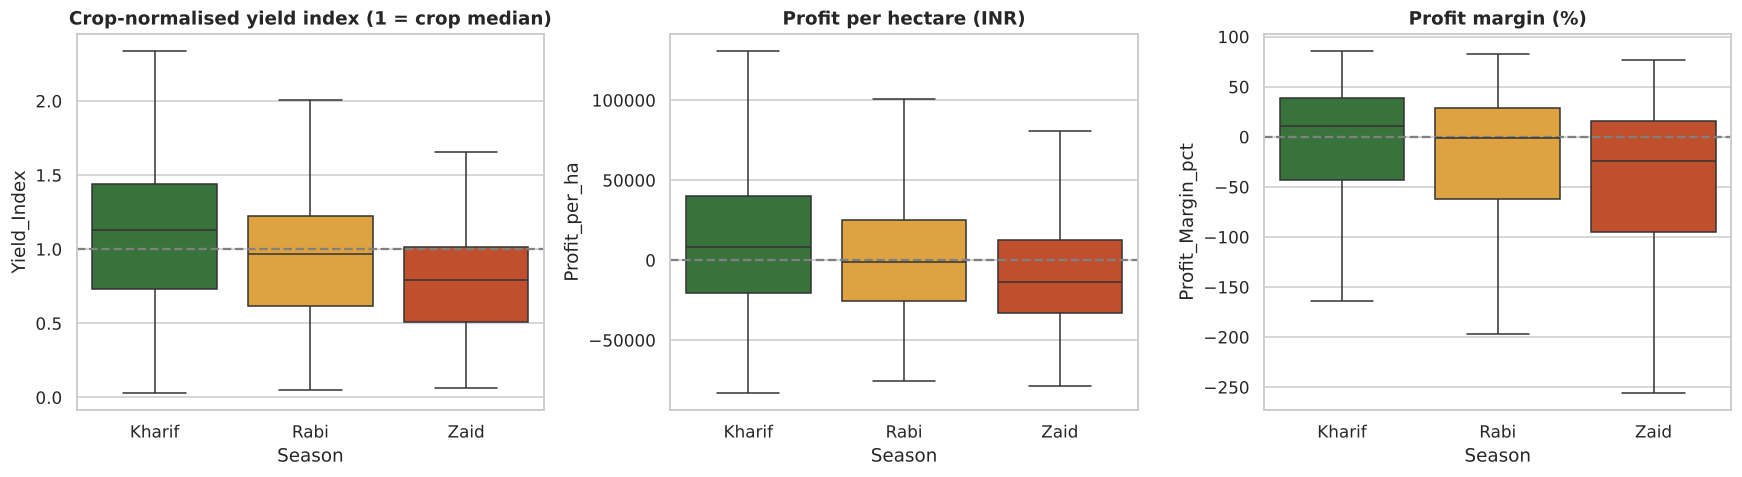

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(data=clean, x="Season", y="Yield_Index", order=SEASON_ORDER, palette=SEASON_COLORS, ax=ax[0], showfliers=False)
ax[0].axhline(1, ls="--", c="grey"); ax[0].set_title("Crop-normalised yield index (1 = crop median)")
sns.boxplot(data=clean, x="Season", y="Profit_per_ha", order=SEASON_ORDER, palette=SEASON_COLORS, ax=ax[1], showfliers=False)
ax[1].axhline(0, ls="--", c="grey"); ax[1].set_title("Profit per hectare (INR)")
sns.boxplot(data=clean, x="Season", y="Profit_Margin_pct", order=SEASON_ORDER, palette=SEASON_COLORS, ax=ax[2], showfliers=False)
ax[2].axhline(0, ls="--", c="grey"); ax[2].set_title("Profit margin (%)")
savefig("07_performance_by_season")

In [23]:
# Raw yield by season within each crop (avoids the sugarcane distortion)
yt = clean.pivot_table(index="Crop", columns="Season", values="Yield_Tonnes_Ha", aggfunc="median", observed=True).round(2)
yt["Kharif_vs_Zaid_%"] = ((yt["Kharif"] / yt["Zaid"] - 1) * 100).round(1)
yt

Season,Kharif,Rabi,Zaid,Kharif_vs_Zaid_%
Crop,,,,
Chilli,1.77,1.56,1.23,43.9
Cotton,1.44,1.21,0.96,50.0
Groundnut,1.52,1.30,1.10,38.2
Maize,3.12,2.82,2.26,38.1
Pulses,1.09,0.90,0.66,65.2
Rice,2.88,2.38,1.94,48.5
Sugarcane,56.65,45.46,38.78,46.1
Wheat,2.36,2.22,1.84,28.3


### 6.4 Resource use and risk by season

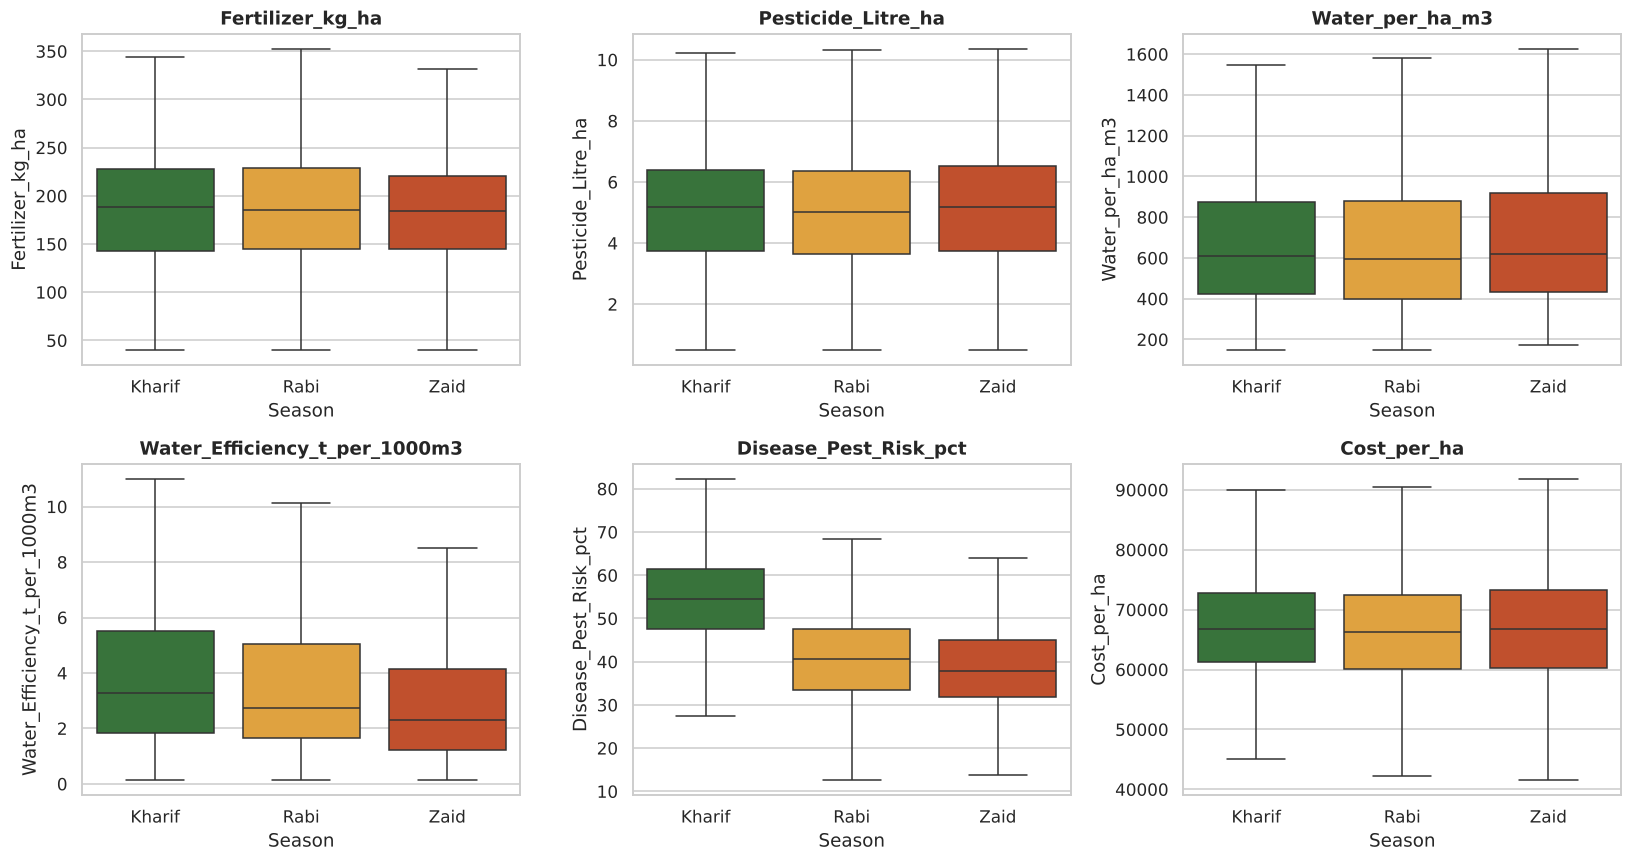

,Fertilizer_kg_ha,Pesticide_Litre_ha,Water_per_ha_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct,Cost_per_ha
Season,,,,,,
Kharif,187.08,5.08,758.17,5.89,54.47,66900.98
Rabi,185.41,5.02,763.36,5.19,40.48,66295.24
Zaid,184.64,5.17,792.58,4.41,38.22,66937.94


In [24]:
res = ["Fertilizer_kg_ha","Pesticide_Litre_ha","Water_per_ha_m3","Water_Efficiency_t_per_1000m3","Disease_Pest_Risk_pct","Cost_per_ha"]
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for a, col in zip(ax.ravel(), res):
    sns.boxplot(data=clean, x="Season", y=col, order=SEASON_ORDER, palette=SEASON_COLORS, ax=a, showfliers=False); a.set_title(col)
savefig("08_resources_by_season")
clean.groupby("Season", observed=True)[res].mean().round(2)

### 6.5 Market price by season

Season       Kharif      Rabi     Zaid  Zaid_vs_Kharif_%
Crop                                                    
Chilli     102884.0  105471.0  98904.0              -3.9
Cotton      68394.0   68296.0  67890.0              -0.7
Groundnut   56604.0   56661.0  54868.0              -3.1
Maize       20928.0   20979.0  21050.0               0.6
Pulses      71261.0   71319.0  69900.0              -1.9
Rice        21797.0   22137.0  22134.0               1.5
Sugarcane    3466.0    3487.0   3548.0               2.4
Wheat       23758.0   24174.0  23830.0               0.3


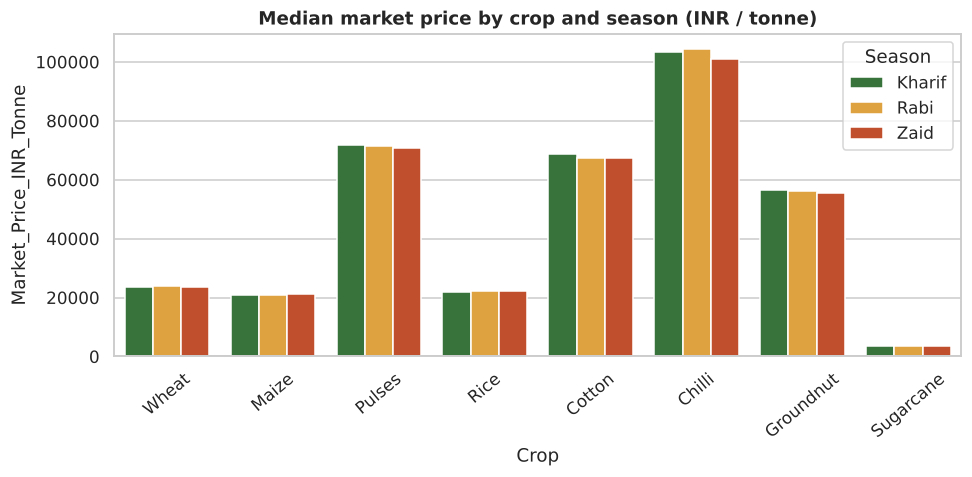

In [25]:
price = clean.pivot_table(index="Crop", columns="Season", values="Market_Price_INR_Tonne", aggfunc="median", observed=True).round(0)
price["Zaid_vs_Kharif_%"] = ((price["Zaid"]/price["Kharif"]-1)*100).round(1)
print(price)
plt.figure(figsize=(9,4.5))
sns.barplot(data=clean, x="Crop", y="Market_Price_INR_Tonne", hue="Season", hue_order=SEASON_ORDER, palette=SEASON_COLORS, errorbar=None)
plt.xticks(rotation=40); plt.title("Median market price by crop and season (INR / tonne)")
savefig("09_price_by_crop_season")

## 7. Statistical significance testing
Visible differences are only meaningful if they are unlikely to be chance. Because yield, profit and risk are skewed, the **Kruskal-Wallis** test (non-parametric ANOVA) is used, followed by **pairwise Mann-Whitney U** tests with a Bonferroni correction. For the profitable-share comparison a **chi-square test** is used.

In [26]:
metrics = ["Yield_Index","Profit_per_ha","Profit_Margin_pct","Cost_per_ha","Rainfall_mm","Avg_Temperature_C","Humidity_pct","Sunlight_Hours_Day",
           "Soil_Moisture_pct","Water_Efficiency_t_per_1000m3","Disease_Pest_Risk_pct","Fertilizer_kg_ha","Pesticide_Litre_ha"]
groups = {s: clean.loc[clean.Season == s] for s in SEASON_ORDER}
rows = []
for m in metrics:
    H, p = stats.kruskal(*[g[m] for g in groups.values()])
    n = len(clean); eps2 = (H - 3 + 1) / (n - 3)          # epsilon-squared effect size
    rows.append({"Metric": m, "H": round(H, 1), "p_value": p, "Effect_size_eps2": round(eps2, 3), "Significant (p<0.05)": p < 0.05})
kw = pd.DataFrame(rows).sort_values("Effect_size_eps2", ascending=False)
kw["p_value"] = kw["p_value"].apply(lambda x: f"{x:.2e}")
kw

,Metric,H,p_value,Effect_size_eps2,Significant (p<0.05)
4,Rainfall_mm,2600.1,0.00e+00,0.650,True
5,Avg_Temperature_C,2386.0,0.00e+00,0.596,True
8,Soil_Moisture_pct,1858.4,0.00e+00,0.464,True
6,Humidity_pct,1845.5,0.00e+00,0.461,True
10,Disease_Pest_Risk_pct,1430.9,1.91e-311,0.357,True
7,Sunlight_Hours_Day,832.3,1.87e-181,0.208,True
0,Yield_Index,254.1,6.62e-56,0.063,True
1,Profit_per_ha,97.1,8.10e-22,0.024,True
2,Profit_Margin_pct,98.1,5.08e-22,0.024,True
9,Water_Efficiency_t_per_1000m3,56.8,4.61e-13,0.014,True


In [27]:
# Pairwise comparisons (Bonferroni, 3 pairs)
pairs = list(combinations(SEASON_ORDER, 2))
out = []
for m in ["Yield_Index", "Profit_per_ha", "Profit_Margin_pct", "Disease_Pest_Risk_pct", "Water_Efficiency_t_per_1000m3"]:
    for a, b in pairs:
        u, p = stats.mannwhitneyu(groups[a][m], groups[b][m])
        out.append({"Metric": m, "Pair": f"{a} vs {b}", "Median_A": round(groups[a][m].median(), 2), "Median_B": round(groups[b][m].median(), 2),
                    "p_bonferroni": min(p * 3, 1.0)})
pw = pd.DataFrame(out); pw["Significant"] = pw["p_bonferroni"] < 0.05; pw["p_bonferroni"] = pw["p_bonferroni"].apply(lambda x: f"{x:.2e}")
pw

,Metric,Pair,Median_A,Median_B,p_bonferroni,Significant
0,Yield_Index,Kharif vs Rabi,1.13,0.97,1.30e-22,True
1,Yield_Index,Kharif vs Zaid,1.13,0.79,1.32e-48,True
2,Yield_Index,Rabi vs Zaid,0.97,0.79,6.85e-18,True
3,Profit_per_ha,Kharif vs Rabi,8340.45,-894.33,5.32e-08,True
4,Profit_per_ha,Kharif vs Zaid,8340.45,-13760.26,3.24e-20,True
5,Profit_per_ha,Rabi vs Zaid,-894.33,-13760.26,2.21e-08,True
6,Profit_Margin_pct,Kharif vs Rabi,11.09,-1.34,5.09e-08,True
7,Profit_Margin_pct,Kharif vs Zaid,11.09,-24.59,1.69e-20,True
8,Profit_Margin_pct,Rabi vs Zaid,-1.34,-24.59,2.05e-08,True
9,Disease_Pest_Risk_pct,Kharif vs Rabi,54.50,40.60,2.42e-250,True


In [28]:
ct = pd.crosstab(clean["Season"], clean["Is_Profitable"])
chi2, p, dof, _ = stats.chi2_contingency(ct)
print(ct.rename(columns={0: "Loss", 1: "Profit"}))
print(f"\nChi-square = {chi2:.1f}, dof = {dof}, p = {p:.2e}  -> profitability depends on season: {p < 0.05}")

Is_Profitable  Loss  Profit
Season                     
Kharif          751    1028
Rabi            832     795
Zaid            383     211

Chi-square = 92.6, dof = 2, p = 7.62e-21  -> profitability depends on season: True


## 8. Deeper cuts: Crop, Irrigation and State × Season

### 8.1 Crop × Season

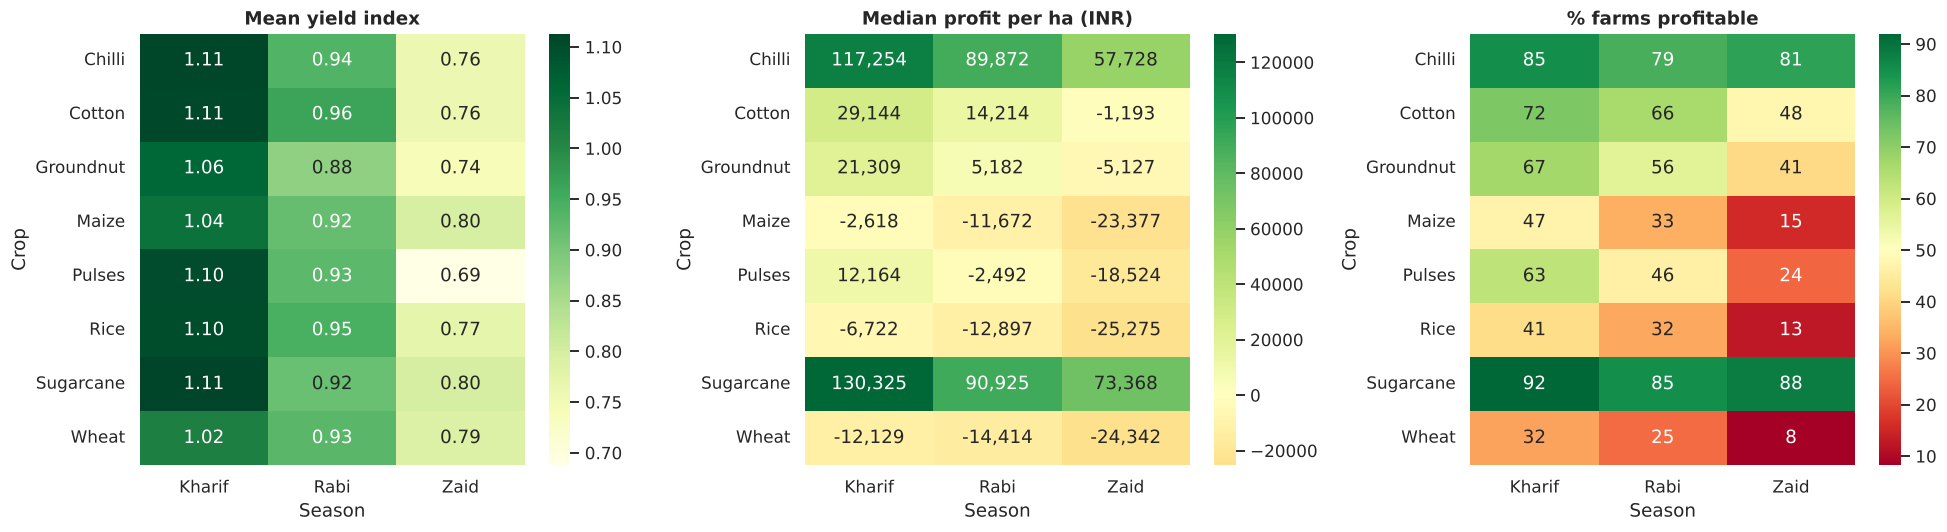

In [29]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
h1 = clean.pivot_table(index="Crop", columns="Season", values="Yield_Index", aggfunc="mean", observed=True)[SEASON_ORDER]
h2 = clean.pivot_table(index="Crop", columns="Season", values="Profit_per_ha", aggfunc="median", observed=True)[SEASON_ORDER]
h3 = clean.pivot_table(index="Crop", columns="Season", values="Is_Profitable", aggfunc="mean", observed=True)[SEASON_ORDER] * 100
sns.heatmap(h1, annot=True, fmt=".2f", cmap="YlGn", ax=ax[0]); ax[0].set_title("Mean yield index")
sns.heatmap(h2, annot=True, fmt=",.0f", cmap="RdYlGn", center=0, ax=ax[1]); ax[1].set_title("Median profit per ha (INR)")
sns.heatmap(h3, annot=True, fmt=".0f", cmap="RdYlGn", center=50, ax=ax[2]); ax[2].set_title("% farms profitable")
savefig("10_crop_season_heatmaps")

In [30]:
best = (clean.groupby(["Season", "Crop"], observed=True).agg(Farms=("Farm_ID","count"), Median_Profit_per_ha=("Profit_per_ha","median"),
        Pct_Profitable=("Is_Profitable", lambda s: s.mean()*100)).round(1).reset_index())
for s in SEASON_ORDER:
    print(f"\n=== {s}: crops ranked by median profit per ha ===")
    print(best[best.Season == s].sort_values("Median_Profit_per_ha", ascending=False).drop(columns="Season").to_string(index=False))


=== Kharif: crops ranked by median profit per ha ===
     Crop  Farms  Median_Profit_per_ha  Pct_Profitable
Sugarcane    125              130325.0            92.0
   Chilli    185              117254.2            85.4
   Cotton    215               29143.9            72.1
Groundnut    193               21308.7            66.8
   Pulses    221               12163.7            62.9
    Maize    234               -2618.0            46.6
     Rice    314               -6721.9            41.4
    Wheat    292              -12129.1            31.8

=== Rabi: crops ranked by median profit per ha ===
     Crop  Farms  Median_Profit_per_ha  Pct_Profitable
Sugarcane    129               90924.7            85.3
   Chilli    163               89871.6            78.5
   Cotton    201               14213.7            66.2
Groundnut    177                5182.3            56.5
   Pulses    213               -2492.1            46.0
    Maize    233              -11672.0            33.5
     Rice    2

### 8.2 Irrigation method × Season

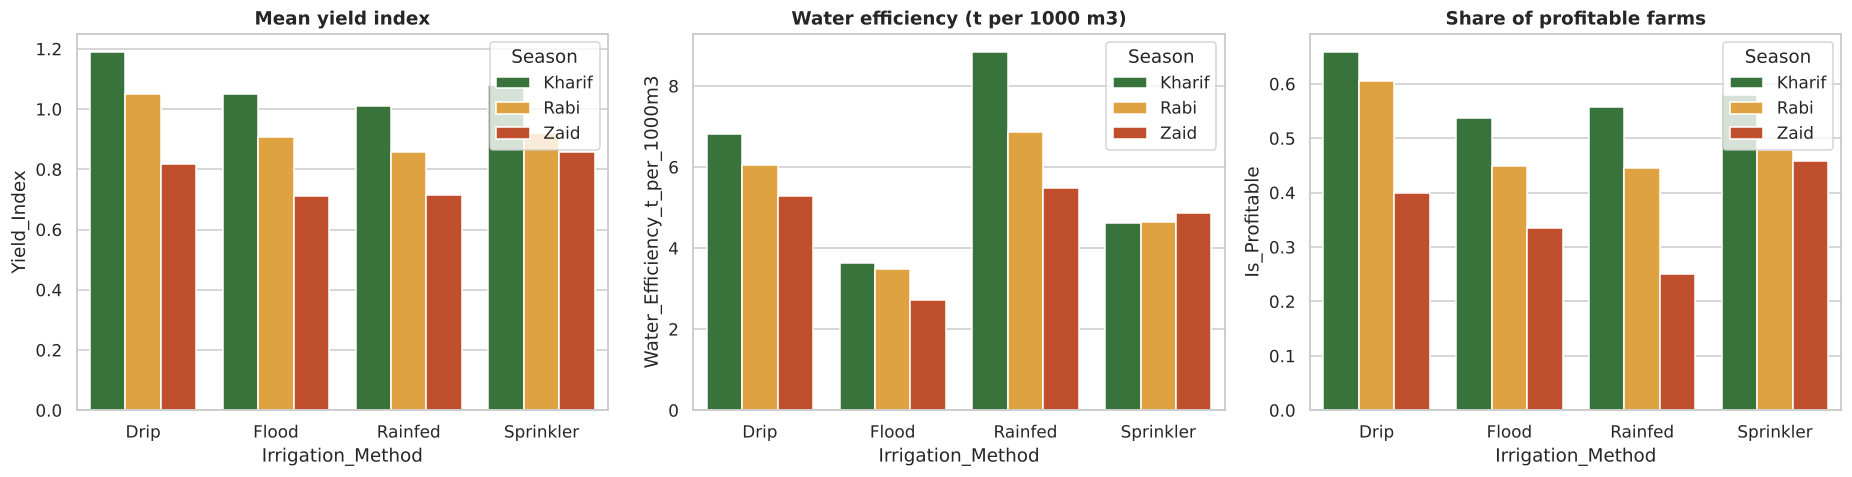

Irrigation_Method  Drip  Flood  Rainfed  Sprinkler
Season                                            
Kharif             22.8   33.2     26.0       18.0
Rabi               22.7   32.3     26.9       18.0
Zaid               23.6   32.7     23.6       20.2


Yield_Index        Water_per_ha_m3         Water_Efficiency_t_per_1000m3        Profit_per_ha          
                         mean median            mean  median                          mean median          mean    median
Irrigation_Method                                                                                                        
Drip                     1.08   1.12          727.33  529.84                          6.27   3.26      25606.90  11176.94
Flood                    0.94   0.98         1029.44  772.50                          3.44   1.95       8890.04  -2185.92
Rainfed                  0.91   0.93          445.82  329.25                          7.56   4.58       9481.02  -2492.15
Sprinkler                0.98   1.02          794.81  589.87                          4.67   2.65      12635.01   1494.28

In [31]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.barplot(data=clean, x="Irrigation_Method", y="Yield_Index", hue="Season", hue_order=SEASON_ORDER, palette=SEASON_COLORS, errorbar=None, ax=ax[0]); ax[0].set_title("Mean yield index")
sns.barplot(data=clean, x="Irrigation_Method", y="Water_Efficiency_t_per_1000m3", hue="Season", hue_order=SEASON_ORDER, palette=SEASON_COLORS, errorbar=None, ax=ax[1]); ax[1].set_title("Water efficiency (t per 1000 m3)")
sns.barplot(data=clean, x="Irrigation_Method", y="Is_Profitable", hue="Season", hue_order=SEASON_ORDER, palette=SEASON_COLORS, errorbar=None, ax=ax[2]); ax[2].set_title("Share of profitable farms")
savefig("11_irrigation_season")
print(pd.crosstab(clean["Season"], clean["Irrigation_Method"], normalize="index").mul(100).round(1))
clean.groupby("Irrigation_Method")[["Yield_Index", "Water_per_ha_m3", "Water_Efficiency_t_per_1000m3", "Profit_per_ha"]].agg(["mean", "median"]).round(2)

### 8.3 State × Season

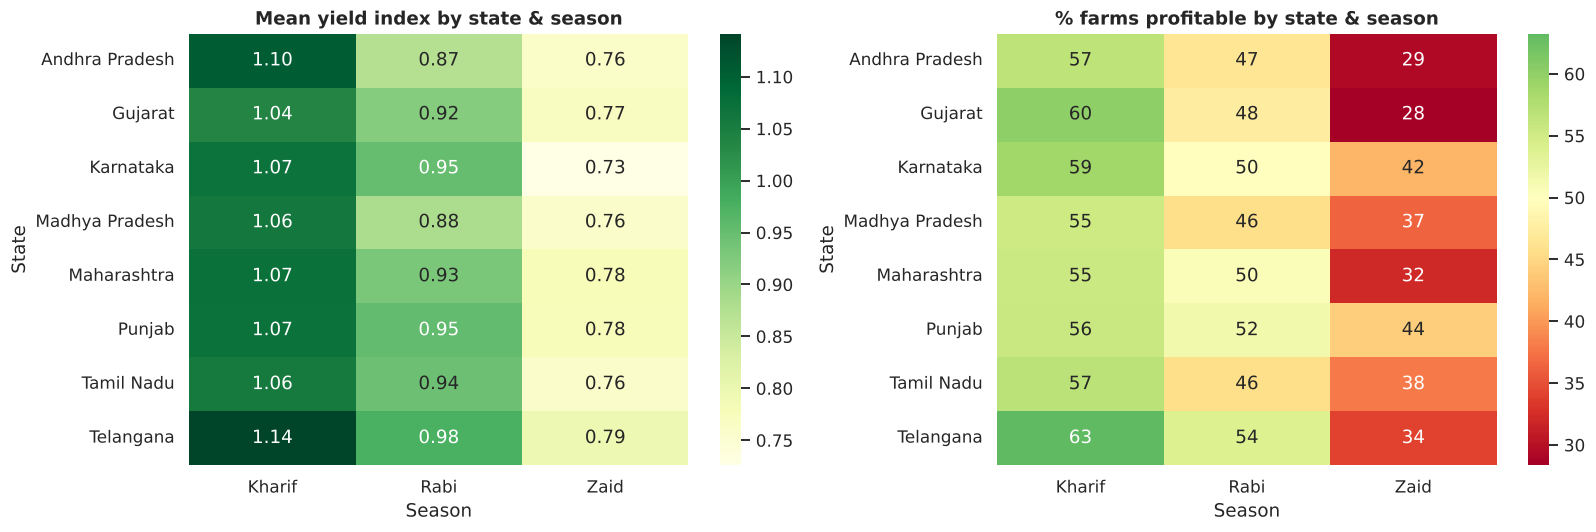

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
s1 = clean.pivot_table(index="State", columns="Season", values="Yield_Index", aggfunc="mean", observed=True)[SEASON_ORDER]
s2 = clean.pivot_table(index="State", columns="Season", values="Is_Profitable", aggfunc="mean", observed=True)[SEASON_ORDER] * 100
sns.heatmap(s1, annot=True, fmt=".2f", cmap="YlGn", ax=ax[0]); ax[0].set_title("Mean yield index by state & season")
sns.heatmap(s2, annot=True, fmt=".0f", cmap="RdYlGn", center=50, ax=ax[1]); ax[1].set_title("% farms profitable by state & season")
savefig("12_state_season")

In [33]:
st = stats.kruskal(*[clean.loc[clean.State == s, "Yield_Index"] for s in clean.State.unique()])
print(f"Does State alone change the yield index?  Kruskal-Wallis p = {st.pvalue:.3f}  ->  {'Yes' if st.pvalue < 0.05 else 'No significant state effect'}")

Does State alone change the yield index?  Kruskal-Wallis p = 0.305  ->  No significant state effect


## 9. Drivers of performance

### 9.1 Correlation analysis

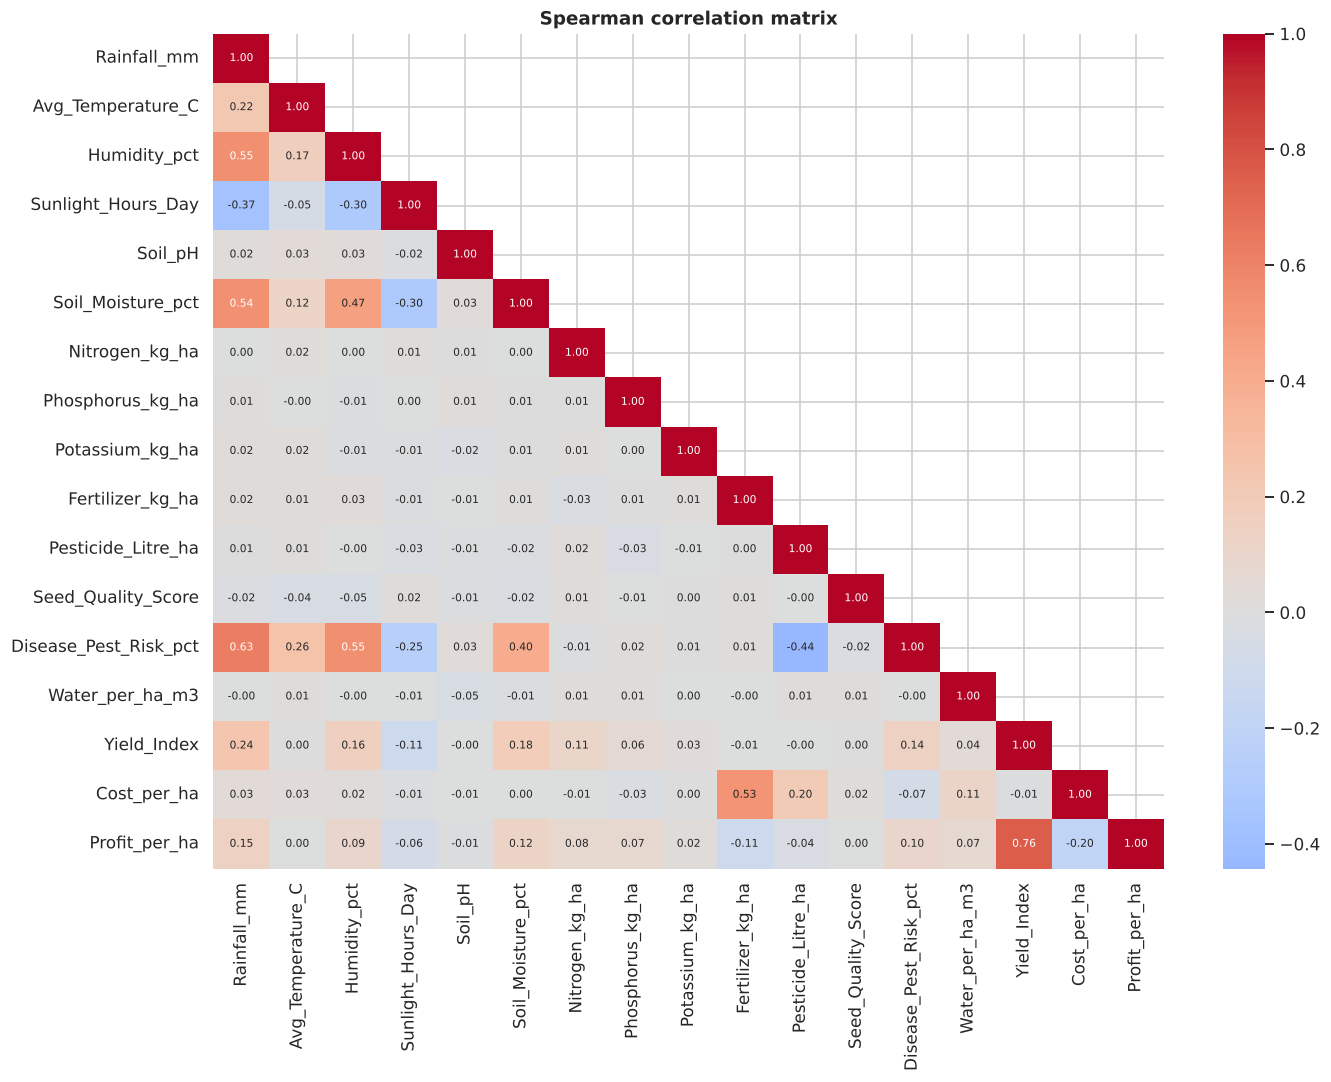

Correlation with Yield_Index:
Profit_per_ha            0.763
Rainfall_mm              0.239
Soil_Moisture_pct        0.182
Humidity_pct             0.163
Disease_Pest_Risk_pct    0.140
Sunlight_Hours_Day      -0.113
Nitrogen_kg_ha           0.105
Phosphorus_kg_ha         0.064

Correlation with Profit_per_ha:
Yield_Index              0.763
Cost_per_ha             -0.196
Rainfall_mm              0.146
Soil_Moisture_pct        0.116
Fertilizer_kg_ha        -0.114
Disease_Pest_Risk_pct    0.098
Humidity_pct             0.090
Nitrogen_kg_ha           0.077


In [34]:
corr_cols = ["Rainfall_mm","Avg_Temperature_C","Humidity_pct","Sunlight_Hours_Day","Soil_pH","Soil_Moisture_pct","Nitrogen_kg_ha","Phosphorus_kg_ha",
             "Potassium_kg_ha","Fertilizer_kg_ha","Pesticide_Litre_ha","Seed_Quality_Score","Disease_Pest_Risk_pct","Water_per_ha_m3",
             "Yield_Index","Cost_per_ha","Profit_per_ha"]
corr = clean[corr_cols].corr(method="spearman")
plt.figure(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7}, mask=np.triu(np.ones_like(corr, bool), 1))
plt.title("Spearman correlation matrix")
savefig("13_correlation_heatmap")

print("Correlation with Yield_Index:")
print(corr["Yield_Index"].drop("Yield_Index").sort_values(key=abs, ascending=False).round(3).head(8).to_string())
print("\nCorrelation with Profit_per_ha:")
print(corr["Profit_per_ha"].drop("Profit_per_ha").sort_values(key=abs, ascending=False).round(3).head(8).to_string())

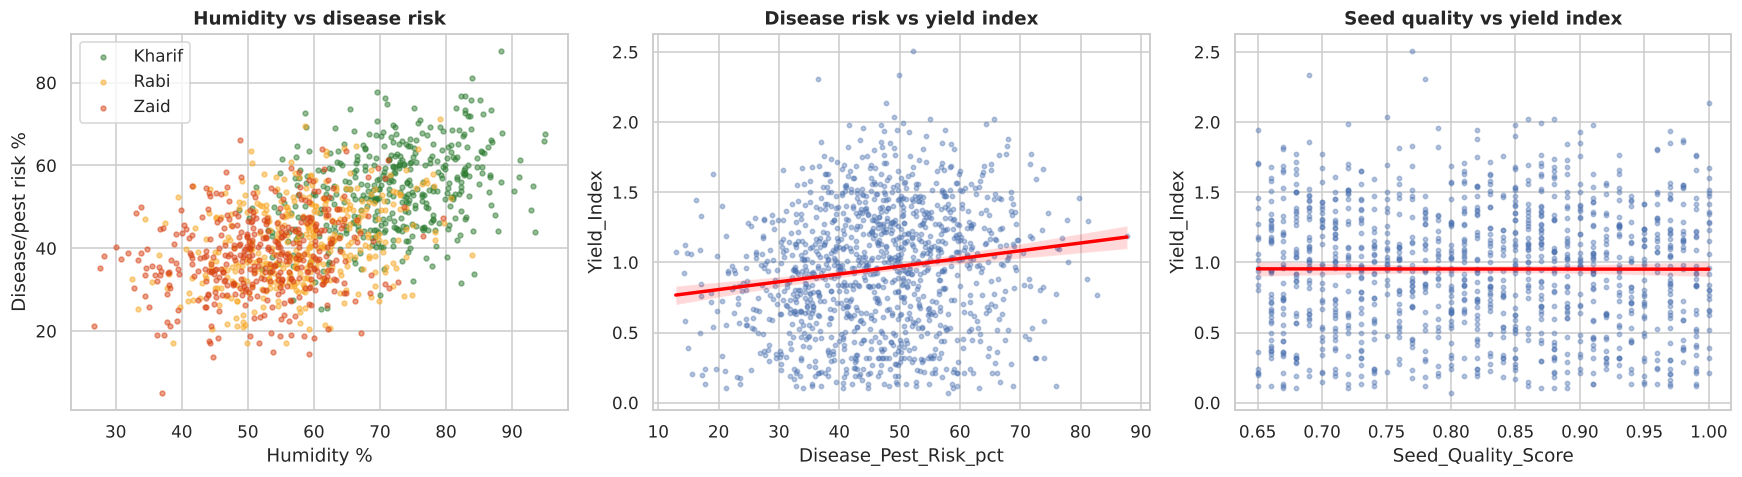

In [35]:
# Disease/pest risk: which conditions raise it, and does it hurt yield?
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for s in SEASON_ORDER:
    d = clean[clean.Season == s].sample(400, random_state=1)
    ax[0].scatter(d["Humidity_pct"], d["Disease_Pest_Risk_pct"], s=10, alpha=.5, c=SEASON_COLORS[s], label=s)
ax[0].set_xlabel("Humidity %"); ax[0].set_ylabel("Disease/pest risk %"); ax[0].set_title("Humidity vs disease risk"); ax[0].legend()
sns.regplot(data=clean.sample(1200, random_state=1), x="Disease_Pest_Risk_pct", y="Yield_Index", scatter_kws={"s": 8, "alpha": .4}, line_kws={"color": "red"}, ax=ax[1]); ax[1].set_title("Disease risk vs yield index")
sns.regplot(data=clean.sample(1200, random_state=1), x="Seed_Quality_Score", y="Yield_Index", scatter_kws={"s": 8, "alpha": .4}, line_kws={"color": "red"}, ax=ax[2]); ax[2].set_title("Seed quality vs yield index")
savefig("14_risk_and_seed")

### 9.2 What drives yield? — Random Forest feature importance

Random Forest R2 on held-out data: 0.895


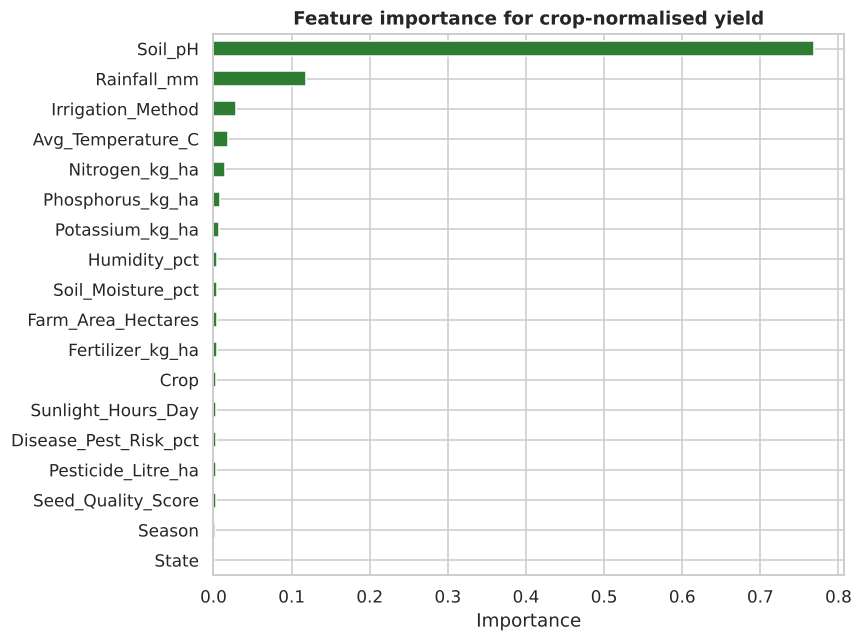

Soil_pH              0.769
Rainfall_mm          0.118
Irrigation_Method    0.029
Avg_Temperature_C    0.019
Nitrogen_kg_ha       0.015
Phosphorus_kg_ha     0.008
Potassium_kg_ha      0.007
Humidity_pct         0.004
dtype: float64

In [36]:
feats = ["Season","Crop","Irrigation_Method","State","Rainfall_mm","Avg_Temperature_C","Humidity_pct","Sunlight_Hours_Day","Soil_pH","Soil_Moisture_pct",
         "Nitrogen_kg_ha","Phosphorus_kg_ha","Potassium_kg_ha","Fertilizer_kg_ha","Pesticide_Litre_ha","Seed_Quality_Score","Disease_Pest_Risk_pct","Farm_Area_Hectares"]
X = pd.get_dummies(clean[feats].astype({"Season": str}), columns=["Season","Crop","Irrigation_Method","State"], drop_first=False)
y = clean["Yield_Index"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42)
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1).fit(Xtr, ytr)
print(f"Random Forest R2 on held-out data: {r2_score(yte, rf.predict(Xte)):.3f}")

imp = pd.Series(rf.feature_importances_, index=X.columns)
# aggregate dummy columns back to their original feature
agg = imp.groupby(lambda c: next((f for f in ["Season","Crop","Irrigation_Method","State"] if c.startswith(f + "_")), c)).sum().sort_values()
plt.figure(figsize=(8, 6)); agg.plot.barh(color="#2E7D32"); plt.title("Feature importance for crop-normalised yield"); plt.xlabel("Importance")
savefig("15_feature_importance")
agg.sort_values(ascending=False).round(3).head(8)

In [37]:
# Does the effect of season survive after controlling for weather? Compare yield index across seasons at similar rainfall levels.
t = clean.pivot_table(index="Rainfall_Category", columns="Season", values="Yield_Index", aggfunc=["mean", "count"], observed=True).round(2)
t

mean              count               
Season             Kharif  Rabi  Zaid Kharif    Rabi   Zaid
Rainfall_Category                                          
Low (<300)           0.74  0.77  0.68    3.0   354.0  318.0
Moderate (300-600)   1.08  0.95  0.85  145.0  1005.0  258.0
High (600-900)       1.16  1.07  1.11  942.0   257.0   18.0
Very high (>900)     0.97  1.02   NaN  689.0    11.0    NaN

### 9.3 Non-linear effects: soil pH, rainfall and temperature
The Random Forest ranks **soil pH** far above every other variable, yet its linear correlation with yield is weak. That combination signals a **bell-shaped (optimum) relationship** — too acidic or too alkaline both hurt. Binning the variables shows the shape directly.

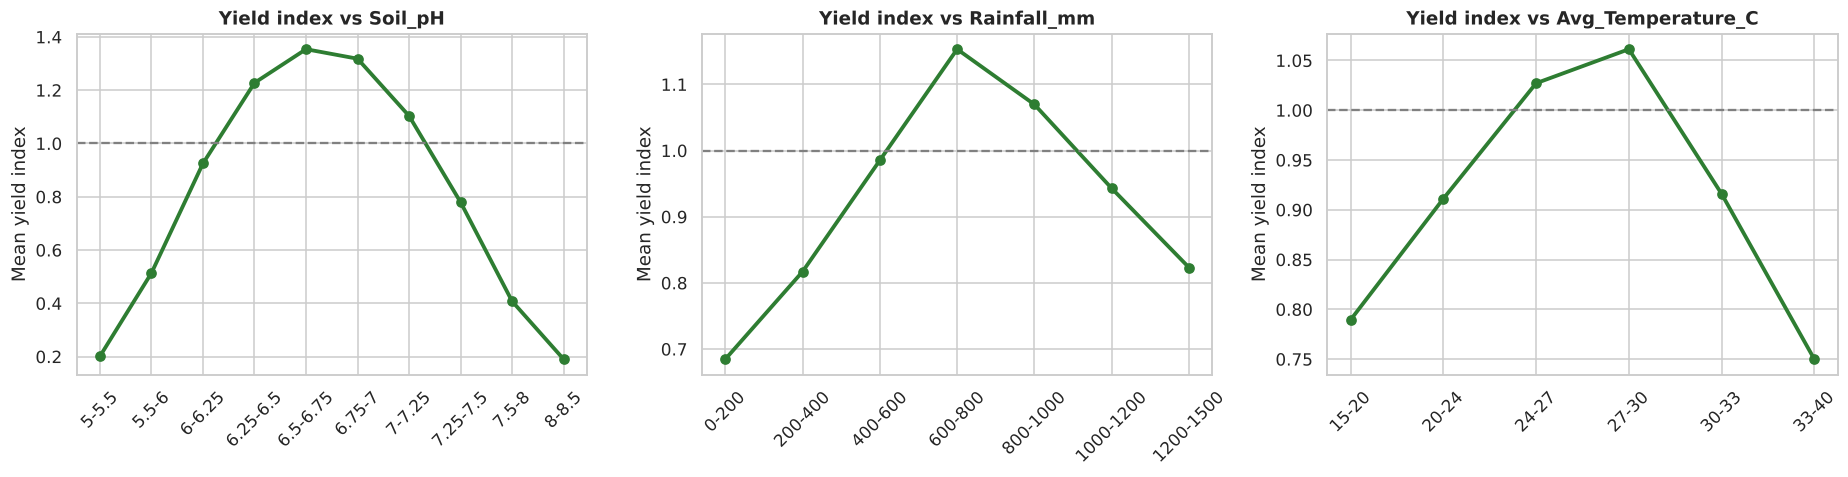

         Farms  Yield_Index  Pct_Profitable
pH_band                                    
<6.0       556         0.44           12.41
6.0-6.5    972         1.09           59.88
6.5-7.0   1209         1.34           78.49
7.0-7.5    830         0.97           49.16
>7.5       433         0.36            6.00

Mean soil pH by season: {'Kharif': 6.73, 'Rabi': 6.67, 'Zaid': 6.69} -> soil pH is not season-dependent


In [38]:
bins = {"Soil_pH": [5, 5.5, 6, 6.25, 6.5, 6.75, 7, 7.25, 7.5, 8, 8.5],
        "Rainfall_mm": [0, 200, 400, 600, 800, 1000, 1200, 1500],
        "Avg_Temperature_C": [15, 20, 24, 27, 30, 33, 40]}
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for a, (col, b) in zip(ax, bins.items()):
    g = clean.assign(bin=pd.cut(clean[col], b)).groupby("bin", observed=True)["Yield_Index"].agg(["mean", "count"])
    g = g[g["count"] >= 30]
    a.plot(range(len(g)), g["mean"], marker="o", color="#2E7D32", lw=2.5)
    a.set_xticks(range(len(g))); a.set_xticklabels([f"{i.left:g}-{i.right:g}" for i in g.index], rotation=45)
    a.axhline(1, ls="--", c="grey"); a.set_title(f"Yield index vs {col}"); a.set_ylabel("Mean yield index")
savefig("16_optimum_curves")

ph = clean.assign(pH_band=pd.cut(clean["Soil_pH"], [5, 6, 6.5, 7, 7.5, 8.5], labels=["<6.0","6.0-6.5","6.5-7.0","7.0-7.5",">7.5"]))
print(ph.groupby("pH_band", observed=True).agg(Farms=("Farm_ID","count"), Yield_Index=("Yield_Index","mean"), Pct_Profitable=("Is_Profitable", lambda s: s.mean()*100)).round(2))
print("\nMean soil pH by season:", clean.groupby("Season", observed=True)["Soil_pH"].mean().round(2).to_dict(), "-> soil pH is not season-dependent")

### 9.4 Is the seasonal gap just a soil effect?
Soil pH is spread identically across seasons, so it cannot explain the seasonal gap — but we can confirm by restricting the analysis to farms with **near-ideal pH (6.2–7.0)** and comparing seasons again.

Farms with ideal soil pH (6.2-7.0):
        Farms  Yield_Index  Pct_Profitable
Season                                    
Kharif    838         1.43           83.53
Rabi      736         1.23           73.23
Zaid      292         1.00           51.71

Kruskal-Wallis across seasons (ideal-pH farms only): p = 1.60e-106


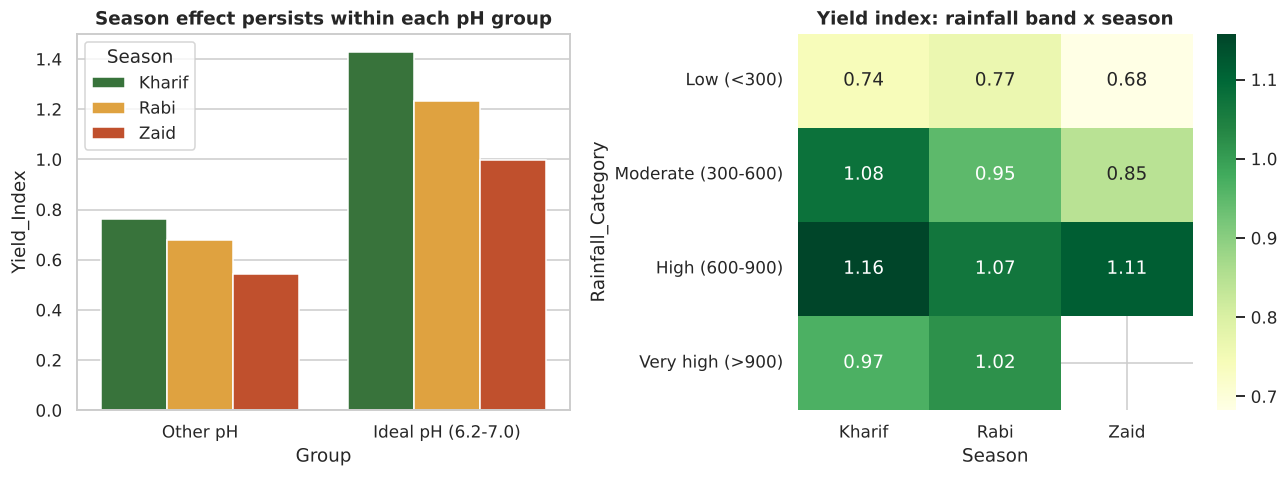

In [39]:
ideal = clean[clean["Soil_pH"].between(6.2, 7.0)]
tab = ideal.groupby("Season", observed=True).agg(Farms=("Farm_ID","count"), Yield_Index=("Yield_Index","mean"), Pct_Profitable=("Is_Profitable", lambda s: s.mean()*100)).round(2)
print("Farms with ideal soil pH (6.2-7.0):"); print(tab)
H, p = stats.kruskal(*[ideal.loc[ideal.Season == s, "Yield_Index"] for s in SEASON_ORDER])
print(f"\nKruskal-Wallis across seasons (ideal-pH farms only): p = {p:.2e}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(data=clean.assign(Group=np.where(clean.Soil_pH.between(6.2, 7.0), "Ideal pH (6.2-7.0)", "Other pH")), x="Group", y="Yield_Index", hue="Season", hue_order=SEASON_ORDER, palette=SEASON_COLORS, errorbar=None, ax=ax[0])
ax[0].set_title("Season effect persists within each pH group")
t = clean.pivot_table(index="Rainfall_Category", columns="Season", values="Yield_Index", aggfunc="mean", observed=True)[SEASON_ORDER]
sns.heatmap(t, annot=True, fmt=".2f", cmap="YlGn", ax=ax[1]); ax[1].set_title("Yield index: rainfall band x season")
savefig("17_season_effect_controlled")

## 10. Key findings & recommendations

### Data quality summary
| Check | Result |
|---|---|
| Duplicates / duplicate IDs | none |
| Missing values | 120 cells (Rainfall 48, Soil moisture 40, Yield 32) — all treated; **0 missing after cleaning** |
| Yield gaps | recovered *exactly* as Production ÷ Area (derived columns reconciled to rounding precision) |
| Outliers | sugarcane's 30–100 t/ha yields are genuine; judged *within crop*, only 1 yield outlier — **no rows deleted** |
| Invalid ranges | none (pH, humidity, moisture, seed score, risk all in range) |
| `District` | not nested in `State` (every district appears in every state) → not used for conclusions |

### Seasonal findings
1. **Kharif is the strongest season, Zaid the weakest — on every performance measure.** Mean crop-normalised yield index is **1.08 (Kharif) > 0.93 (Rabi) > 0.77 (Zaid)**. Median profit per hectare is **+₹8,340 (Kharif), −₹894 (Rabi), −₹13,760 (Zaid)**. Profitable farms: **57.8% → 48.9% → 35.5%**. All pairwise differences are statistically significant (Bonferroni-corrected Mann-Whitney, chi-square p < 0.001).
2. **The gap is driven by yield, not by cost or price.** Cost per hectare is essentially identical in all seasons (~₹66–67k; Kruskal-Wallis p = 0.08, not significant), fertilizer and pesticide use do not differ (p > 0.3), and crop prices barely move between seasons (typically within ±4%). Zaid farms spend the same but harvest less.
3. **The environment differs sharply by season** (largest effect sizes): rainfall ≈ 852 mm (Kharif) vs 436 (Rabi) vs 299 (Zaid); temperature 28.5 / 23.5 / 31.0 °C; soil moisture 31 / 24 / 19 %; humidity 72 / 58 / 52 %. Zaid combines the **least rain and the highest heat** — and the lowest yields.
4. **Every crop yields most in Kharif and least in Zaid.** Kharif's median yield advantage over Zaid ranges from +28% (wheat) to +65% (pulses); +38–50% for most others.
5. **Disease/pest risk is highest in Kharif (54.5%)**, versus 40.5% (Rabi) and 38.2% (Zaid) — the humid monsoon brings both the best yields and the highest biological risk, so crop protection matters most in Kharif.
6. **Water efficiency also declines Kharif → Zaid** (5.9 → 5.2 → 4.4 t per 1000 m³): Zaid uses slightly more water per hectare to produce less.

### Crop-level findings
- **Sugarcane and chilli are the most profitable crops in all three seasons** (≥ 78% of farms profitable); in Zaid they are the **only two crops with a positive median profit** — every other crop loses money at the median.
- **Wheat, rice and maize are loss-making in most conditions** (low market price ₹21–24k/t); in Zaid only 8–16% of these farms earn a profit.
- **Cotton and groundnut are profitable in Kharif and Rabi, but turn marginal/negative in Zaid.**

### Other drivers
- **Soil pH is the single most important factor** (≈77% of Random Forest importance; R² = 0.90 on held-out data). Yield peaks at pH **6.5–7.0** (index ≈ 1.35, ~79% profitable) and falls to about 0.5 or less below pH 6.0 or above 7.5 (≤ 16% of farms profitable).
- **Rainfall and temperature have optimum ranges**: yield is highest at ~600–800 mm and 24–30 °C and falls on both sides.
- **Soil pH is distributed identically across seasons**, and the **season effect persists even on ideal-pH farms** (Kharif 1.43, Rabi 1.23, Zaid 1.00) — so season is a genuine, independent driver.
- **Drip irrigation gives the best yield index (1.08) and profit**; rainfed farms are the most water-efficient (they use the least water) but have the lowest yield. Drip's advantage over flood and rainfed farming holds in every season.
- **State has no significant effect on yield** (p = 0.31) — performance is driven by crop, season, soil and water, not location.

### Recommendations
1. Prioritise **soil-pH correction (liming for acidic, gypsum/sulphur for alkaline soils)** toward 6.5–7.0 — the largest controllable yield lever.
2. In **Zaid**, shift area towards **sugarcane / chilli** and away from rice / wheat / maize; use **drip irrigation** and mulching to cope with low rainfall and high heat.
3. In **Kharif**, invest in **disease and pest management**, because risk peaks while yield potential is highest.
4. Do not assume more input means more profit: fertilizer use shows a weak/negative link with profit per hectare.

### Limitations
- The dataset appears synthetic/simulated (e.g. district–state mismatch; yield floor of 0.30 on 223 farms; very regular distributions) — conclusions describe this dataset and should be validated on real multi-year data before field use.
- Each farm appears once (one season), so this is a cross-sectional comparison, not a time series; correlation ≠ causation.